In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [3]:
df = pd.read_csv("../../course_assignments/homework9/solar_system.csv")

In [4]:
print(df.shape)

(20, 11)


In [5]:
#20 rows and 11 columns

In [7]:
print(df.head())

                Attribute Mercury  Venus  Earth   Moon   Mars Jupiter  Saturn  \
0          Mass (10^24kg)   0.330   4.87   5.97  0.073  0.642    1898     568   
1           Diameter (km)    4879  12104  12756   3475   6792  142984  120536   
2        Density (kg/m^3)    5429   5243   5514   3340   3934    1326     687   
3         Gravity (m/s^2)     3.7    8.9    9.8    1.6    3.7    23.1     9.0   
4  Escape Velocity (km/s)     4.3   10.4   11.2    2.4    5.0    59.5    35.5   

  Uranus Neptune   Pluto  
0   86.8     102  0.0130  
1  51118   49528    2376  
2   1270    1638    1850  
3    8.7    11.0     0.7  
4   21.3    23.5     1.3  


In [8]:
print(df.tail())

                  Attribute Mercury Venus Earth Moon  Mars  Jupiter   Saturn  \
15     Mean Temperature (C)     167   464    15  -20   -65     -110     -140   
16  Surface Pressure (bars)       0    92     1    0  0.01  Unknown  Unknown   
17          Number of Moons       0     0     1    0     2       95      274   
18             Ring System?      No    No    No   No    No      Yes      Yes   
19   Global Magnetic Field?     Yes    No   Yes   No    No      Yes      Yes   

     Uranus  Neptune    Pluto  
15     -195     -200     -225  
16  Unknown  Unknown  0.00001  
17       28       16        5  
18      Yes      Yes       No  
19      Yes      Yes  Unknown  


In [9]:
print(df.columns)

Index(['Attribute', 'Mercury', 'Venus', 'Earth', 'Moon', 'Mars', 'Jupiter',
       'Saturn', 'Uranus', 'Neptune', 'Pluto'],
      dtype='str')


In [16]:
df = df.set_index("Attribute")
print(list(df.index))

['Mass (10^24kg)', 'Diameter (km)', 'Density (kg/m^3)', 'Gravity (m/s^2)', 'Escape Velocity (km/s)', 'Rotation Period (hours)', 'Length of Day (hours)', 'Distance from Sun (10^6 km)', 'Perihelion (10^6 km)', 'Aphelion (10^6 km)', 'Orbital Period (days)', 'Orbital Velocity (km/s)', 'Orbital Inclination (deg)', 'Orbital Eccentricity', 'Obliquity to Orbit (deg)', 'Mean Temperature (C)', 'Surface Pressure (bars)', 'Number of Moons', 'Ring System?', 'Global Magnetic Field?']


In [18]:
op = df.loc["Orbital Period (days)"].values.astype(float)

In [19]:
p = df.loc["Perihelion (10^6 km)"].values.astype(float)

In [21]:
a = df.loc["Aphelion (10^6 km)"].values.astype(float)

In [22]:
#the point where an obect orbiting is closest to what it orbits. the point where an obect orbiting is futherst from the sun. half longest diameter of eclipse. (sorry the key on my keyboard between h and k isnt working)

In [28]:
semi_maor_axis = pd.Series((p + a) / 2, index = df.columns, name = "Semi Maor Axis (10^6 km)")

In [29]:
df = pd.concat([df, semi_maor_axis.to_frame().T])

In [30]:
print(df.shape)

(21, 10)


In [31]:
#21 rows, 10 columns

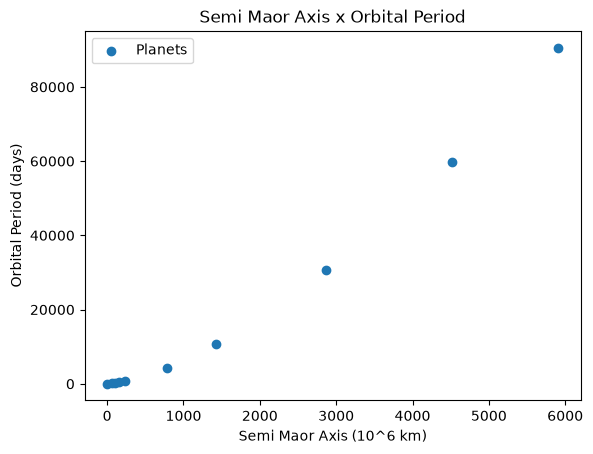

In [32]:
plt.scatter(semi_maor_axis, op, label = "Planets")
plt.xlabel("Semi Maor Axis (10^6 km)")
plt.ylabel("Orbital Period (days)")
plt.title("Semi Maor Axis x Orbital Period")
plt.legend()
plt.show()

In [33]:
def kelpers_third_law(a, m):
    return m * a ** 1.5

In [34]:
popt, pcov = curve_fit(kelpers_third_law, semi_maor_axis, op)

In [35]:
m_fit = popt[0]

In [36]:
print(f"Fit: T = {m_fit:.2f} * a^1.5")

Fit: T = 0.20 * a^1.5


In [44]:
residuals = op - kelpers_third_law(semi_maor_axis, m_fit)
chi2 = np.sum(residuals**2)
dof = len(semi_maor_axis) -  len(popt)
chi2_reduced = chi2 / dof

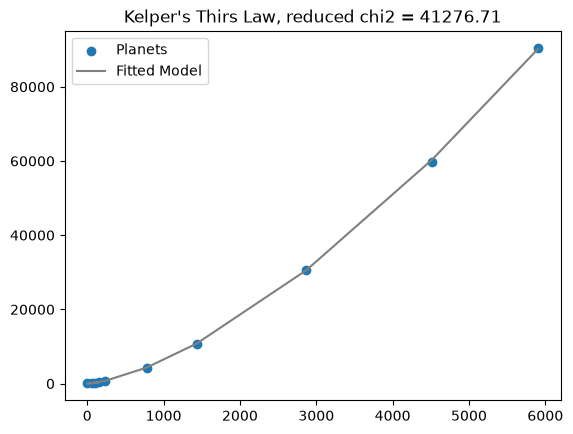

In [45]:
plt.scatter(semi_maor_axis, op, label = "Planets")
plt.plot(semi_maor_axis, kelpers_third_law(semi_maor_axis, m_fit), color = "grey", label = "Fitted Model")
plt.title(f"Kelper's Thirs Law, reduced chi2 = {chi2_reduced:.2f}")
plt.xlabel = ("Semi Maor Axis (10^6 km)")
plt.ylabel = ("Orbital Period (days)")
plt.legend()
plt.show()

In [47]:
df.to_csv("kelper.csv", index = "False")